# 06 · Final evaluation (locked test set, run once) and fairness audit
`T`, `τ`, the fusion model and the fusion decision were all fixed on validation in
notebook 04. Every number below has a 95% bootstrap CI (1,000 resamples over test images).

In [1]:
import sys; sys.path.insert(0, "..")
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, roc_curve
from src.data import CLASSES, FITZ_TO_HAM, load_metadata
from src.fusion import fusion_features, make_xgb
from src.metrics import bootstrap_ci, ece, is_urgent, p_urgent, sens_spec
from src.model import softmax_np

plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight"})
cfg = json.load(open("../models/config.json"))
out = np.load("../models/outputs.npz", allow_pickle=True)
df = load_metadata("../data/ham").set_index("image_id")
test = df.loc[out["test_ids"]]
y = test["y"].to_numpy()

xgb = make_xgb(); xgb.load_model("../models/xgb.json")
base = np.load("../results/baseline_preds.npz", allow_pickle=True)
# align baseline rows (notebook 02 order) to the CNN's test order
order = pd.Series(range(len(base["test_ids"])), index=base["test_ids"]).loc[out["test_ids"]].to_numpy()

p_cnn_raw = softmax_np(out["test_logits"])
p_cnn = softmax_np(out["test_logits"], cfg["T"])
p_fus = xgb.predict_proba(fusion_features(p_cnn, test.reset_index()))
models = {
    "A · always nv": (base["test_A"][order], 0.5),
    "B · metadata LR": (base["test_B"][order], float(base["tau_B"])),
    "CNN (calibrated)": (p_cnn, cfg["tau_cnn"]),
    "CNN + metadata (XGBoost)": (p_fus, cfg["tau_fusion"]),
}

In [2]:
rows = {}
for name, (p, tau) in models.items():
    ci = bootstrap_ci(p, y, tau, n=1000)
    rows[name] = {k: f"{v[0]:.3f} [{v[1]:.3f}, {v[2]:.3f}]" for k, v in ci.items()}
    rows[name]["_raw"] = ci
results = pd.DataFrame({k: {m: v for m, v in r.items() if m != "_raw"} for k, r in rows.items()}).T
results

,sensitivity_urgent,specificity_urgent,auroc_urgent,balanced_accuracy,ece
A · always nv,"0.000 [0.000, 0.000]","1.000 [1.000, 1.000]","0.500 [0.500, 0.500]","0.143 [0.143, 0.143]","0.331 [0.308, 0.353]"
B · metadata LR,"0.922 [0.891, 0.950]","0.371 [0.343, 0.397]","0.768 [0.739, 0.796]","0.383 [0.336, 0.429]","0.106 [0.087, 0.128]"
CNN (calibrated),"0.803 [0.757, 0.846]","0.871 [0.852, 0.890]","0.930 [0.913, 0.945]","0.823 [0.797, 0.848]","0.054 [0.043, 0.073]"
CNN + metadata (XGBoost),"0.898 [0.857, 0.933]","0.815 [0.794, 0.837]","0.938 [0.924, 0.953]","0.818 [0.784, 0.850]","0.043 [0.033, 0.060]"


In [3]:
print("ECE on test, CNN before / after temperature scaling:",
      round(ece(p_cnn_raw, y), 4), "/", round(ece(p_cnn, y), 4))
final_name = "CNN + metadata (XGBoost)" if cfg["use_fusion"] else "CNN (calibrated)"
p_final, tau_final = models[final_name]
print("deployed decision model:", final_name)

ECE on test, CNN before / after temperature scaling: 0.1295 / 0.0539
deployed decision model: CNN (calibrated)


## Confusion matrix and per-class recall (deployed model)

akiec    0.592
bcc      0.769
bkl      0.867
df       1.000
mel      0.643
nv       0.890
vasc     1.000
dtype: float64

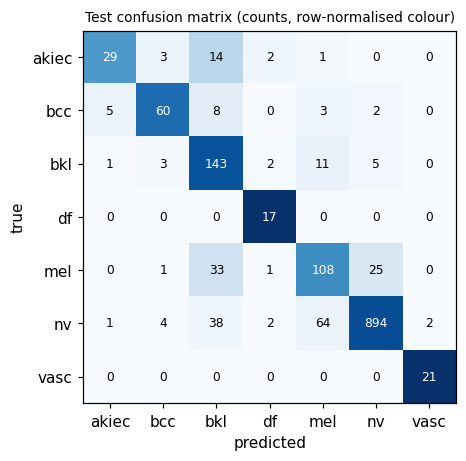

In [4]:
cm = confusion_matrix(y, p_final.argmax(1), labels=range(7))
recall = pd.Series(cm.diagonal() / cm.sum(1), index=CLASSES).round(3)
fig, ax = plt.subplots(figsize=(5, 4.4))
cmn = cm / cm.sum(1, keepdims=True)
ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
for i in range(7):
    for j in range(7):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8, color="white" if cmn[i, j] > .5 else "black")
ax.set_xticks(range(7), CLASSES); ax.set_yticks(range(7), CLASSES)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("Test confusion matrix (counts, row-normalised colour)", fontsize=9)
fig.savefig("../figures/confusion_matrix.png")
recall

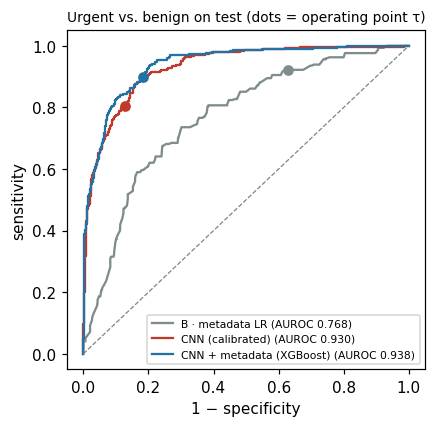

In [5]:
fig, ax = plt.subplots(figsize=(4.2, 4))
for (name, (p, tau)), c in zip(list(models.items())[1:], ["#7f8c8d", "#c0392b", "#2471a3"]):
    fpr, tpr, _ = roc_curve(is_urgent(y), p_urgent(p))
    s, sp = sens_spec(is_urgent(y), p_urgent(p), tau)
    ax.plot(fpr, tpr, c=c, label=f"{name} (AUROC {rows[name]['_raw']['auroc_urgent'][0]:.3f})")
    ax.plot(1 - sp, s, "o", c=c)
ax.plot([0, 1], [0, 1], ls="--", c="gray", lw=.8)
ax.set_xlabel("1 − specificity"); ax.set_ylabel("sensitivity"); ax.legend(fontsize=7, loc="lower right")
ax.set_title("Urgent vs. benign on test (dots = operating point τ)", fontsize=9)
fig.savefig("../figures/roc_urgent.png")

## Subgroups inside HAM10000 (sex, age)
HAM10000 has no skin-type labels, so within-dataset we can only slice by sex and age.

In [6]:
def sub_metrics(mask):
    yu = is_urgent(y[mask]); s, sp = sens_spec(yu, p_urgent(p_final[mask]), tau_final)
    return dict(n=int(mask.sum()), n_urgent=int(yu.sum()), sensitivity=round(s, 3), specificity=round(sp, 3))

age_band = pd.cut(test["age"], [0, 40, 60, 120], labels=["<40", "40–59", "60+"])
sub = {f"sex={s}": sub_metrics((test["sex"] == s).to_numpy()) for s in ["male", "female"]}
sub.update({f"age {a}": sub_metrics((age_band == a).to_numpy()) for a in age_band.cat.categories})
pd.DataFrame(sub).T

,n,n_urgent,sensitivity,specificity
sex=male,780.0,177.0,0.814,0.852
sex=female,715.0,118.0,0.788,0.889
age <40,435.0,32.0,0.594,0.861
age 40–59,625.0,85.0,0.753,0.900
age 60+,431.0,178.0,0.865,0.822


## Fairness audit on Fitzpatrick17k (no retraining)
Clinical photos of conditions that map onto HAM10000 classes, run through the CNN alone
(Fitzpatrick17k has no age/site metadata). Two shifts are mixed together here:
**skin tone** and **clinical photo vs. dermoscopy**. We report urgent sensitivity by
Fitzpatrick type at the deployed CNN threshold.

In [7]:
fz_meta = pd.read_csv("../data/fitz/fitzpatrick17k.csv").drop_duplicates("md5hash").set_index("md5hash")
fz = fz_meta.loc[out["fitz_ids"]].copy()
fz["y"] = fz["label"].map(FITZ_TO_HAM).map(CLASSES.index)
p_fz = softmax_np(out["fitz_logits"], cfg["T"])
fz["p_urgent"] = p_urgent(p_fz)
fz["group"] = pd.cut(fz["fitzpatrick_scale"], [0, 2, 4, 6], labels=["I–II", "III–IV", "V–VI"])
print(len(fz), "images;", fz["label"].map(FITZ_TO_HAM).value_counts().to_dict())

from src.triage import OODDetector
det = OODDetector.load("../models/ood.npz")
fz["ood"] = det.flags(out["fitz_emb"].astype(np.float64), p_fz)["unlike_training"]

def boot_sens(yu, s, tau, n=1000, seed=0):
    r = np.random.default_rng(seed); pos = s[yu == 1]
    sens = (pos >= tau).mean()
    bs = [(r.choice(pos, len(pos)) >= tau).mean() for _ in range(n)]
    return sens, np.percentile(bs, 2.5), np.percentile(bs, 97.5)

fair = []
for g, d in [("HAM10000 test (dermoscopy)", None)] + list(fz.groupby("group", observed=True)):
    if d is None:
        yu, s = is_urgent(y), p_urgent(p_cnn)
        ood_rate = np.nan
    else:
        yu, s = is_urgent(d["y"].to_numpy()), d["p_urgent"].to_numpy()
        ood_rate = d["ood"].mean()
    se, lo, hi = boot_sens(yu, s, cfg["tau_cnn"])
    _, sp = sens_spec(yu, s, cfg["tau_cnn"])
    fair.append(dict(group=g, n=len(yu), n_urgent=int(yu.sum()), sensitivity=se, ci_lo=lo, ci_hi=hi,
                     specificity=sp, flagged_ood=ood_rate))
fair = pd.DataFrame(fair).set_index("group")
fair.round(3)

1916 images; {'bcc': 596, 'mel': 573, 'nv': 236, 'vasc': 188, 'akiec': 175, 'df': 79, 'bkl': 69}


,n,n_urgent,sensitivity,ci_lo,ci_hi,specificity,flagged_ood
group,,,,,,,
HAM10000 test (dermoscopy),1503,295,0.803,0.759,0.844,0.871,NaN
I–II,1122,783,0.714,0.683,0.746,0.634,0.403
III–IV,601,422,0.690,0.647,0.732,0.492,0.383
V–VI,137,92,0.772,0.685,0.859,0.356,0.299


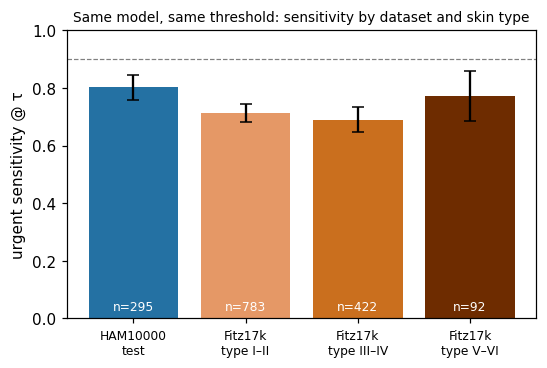

In [8]:
fig, ax = plt.subplots(figsize=(5.5, 3.4))
xs = np.arange(len(fair))
cols = ["#2471a3"] + ["#e59866", "#ca6f1e", "#6e2c00"][: len(fair) - 1]
ax.bar(xs, fair.sensitivity, color=cols, yerr=[fair.sensitivity - fair.ci_lo, fair.ci_hi - fair.sensitivity], capsize=4)
for x, (_, r) in zip(xs, fair.iterrows()):
    ax.text(x, 0.03, f"n={int(r.n_urgent)}", ha="center", color="white", fontsize=8)
ax.axhline(0.9, ls="--", c="gray", lw=.8)
ax.set_xticks(xs, ["HAM10000\ntest"] + [f"Fitz17k\ntype {g}" for g in fair.index[1:]], fontsize=8)
ax.set_ylim(0, 1); ax.set_ylabel("urgent sensitivity @ τ")
ax.set_title("Same model, same threshold: sensitivity by dataset and skin type", fontsize=9)
fig.savefig("../figures/fairness_sensitivity.png")

### HAM10000's own demographic breakdown
Context for the gap above: HAM10000 comes from Austrian and Australian clinics and has no
skin-type labels; it is widely understood to be predominantly lighter skin.

In [9]:
demo = {"sex": df["sex"].value_counts(normalize=True).round(3).to_dict(),
        "age_median": float(df["age"].median()),
        "dataset_origin": "ViDIR Group (Vienna, Austria) and Cliff Rosendahl's practice (Queensland, Australia)"}
demo

{'sex': {'male': 0.54, 'female': 0.455, 'unknown': 0.006},
 'age_median': 50.0,
 'dataset_origin': "ViDIR Group (Vienna, Austria) and Cliff Rosendahl's practice (Queensland, Australia)"}

In [10]:
json.dump({"test_results": {k: v["_raw"] for k, v in rows.items()},
           "deployed": final_name, "per_class_recall": recall.to_dict(),
           "ece_test_before": ece(p_cnn_raw, y), "ece_test_after": ece(p_cnn, y),
           "subgroups": sub, "fairness": fair.reset_index().to_dict("records"), "demographics": demo},
          open("../results/eval.json", "w"), indent=2, default=float)